In [14]:
import gymnasium as gym

%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [71]:
import importlib
from racetrack import RacetrackEnv
from IPython.display import clear_output
from time import sleep


importlib.reload(racetrack)

env = RacetrackEnv()
observation, info = env.reset()
total_reward, done = 0, False
episodes = 0
while episodes != 1000:
    action = env.action_space.sample()  # replace with a policy
    observation, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    done = terminated or truncated
    # Uncomment to get a visual of the car traveling
    clear_output(wait=True)
    sleep(1)
    print(env.render())
    if done:
        if episodes % 100 == 0:
            print(f"Finished iteration {episodes}")
        episodes += 1
        env.reset()

print("Return:", total_reward, info)

KeyboardInterrupt: 

### Racetrack position heatmap

Runs many episodes under a random policy and counts how often each `(x, y)` cell is
visited, then plots it with `seaborn.heatmap` (the same plotting call used for
confusion matrices). Off-track cells are masked out so only the track itself is shown.

soft reset, starting at (5, 0)
doing path
vx: 0 vy:1 x0 5 y0 0
doing path
vx: -1 vy:2 x0 5 y0 1
doing path
vx: -2 vy:3 x0 4 y0 3
doing path
vx: -2 vy:4 x0 2 y0 6
doing path
vx: -3 vy:4 x0 0 y0 10
doing path
vx: -3 vy:4 x0 0 y0 10
doing path
vx: -3 vy:4 x0 0 y0 10
doing path
vx: -3 vy:4 x0 0 y0 10
doing path
vx: -2 vy:4 x0 0 y0 10
doing path
vx: -3 vy:4 x0 0 y0 11
doing path
vx: -3 vy:4 x0 0 y0 11
doing path
vx: -2 vy:3 x0 0 y0 11
doing path
vx: -2 vy:4 x0 0 y0 11
doing path
vx: -2 vy:4 x0 0 y0 12
doing path
vx: -3 vy:4 x0 0 y0 13
doing path
vx: -2 vy:4 x0 0 y0 13
doing path
vx: -3 vy:4 x0 0 y0 14
doing path
vx: -2 vy:4 x0 0 y0 14
doing path
vx: -1 vy:4 x0 0 y0 15
doing path
vx: -2 vy:4 x0 0 y0 17
doing path
vx: -2 vy:4 x0 0 y0 18
doing path
vx: -3 vy:4 x0 0 y0 19
doing path
vx: -3 vy:4 x0 0 y0 19
doing path
vx: -4 vy:4 x0 0 y0 19
doing path
vx: -4 vy:4 x0 0 y0 19
doing path
vx: -3 vy:4 x0 0 y0 19
doing path
vx: -3 vy:3 x0 0 y0 19
doing path
vx: -3 vy:2 x0 0 y0 19
doing path
vx: -4 vy:1

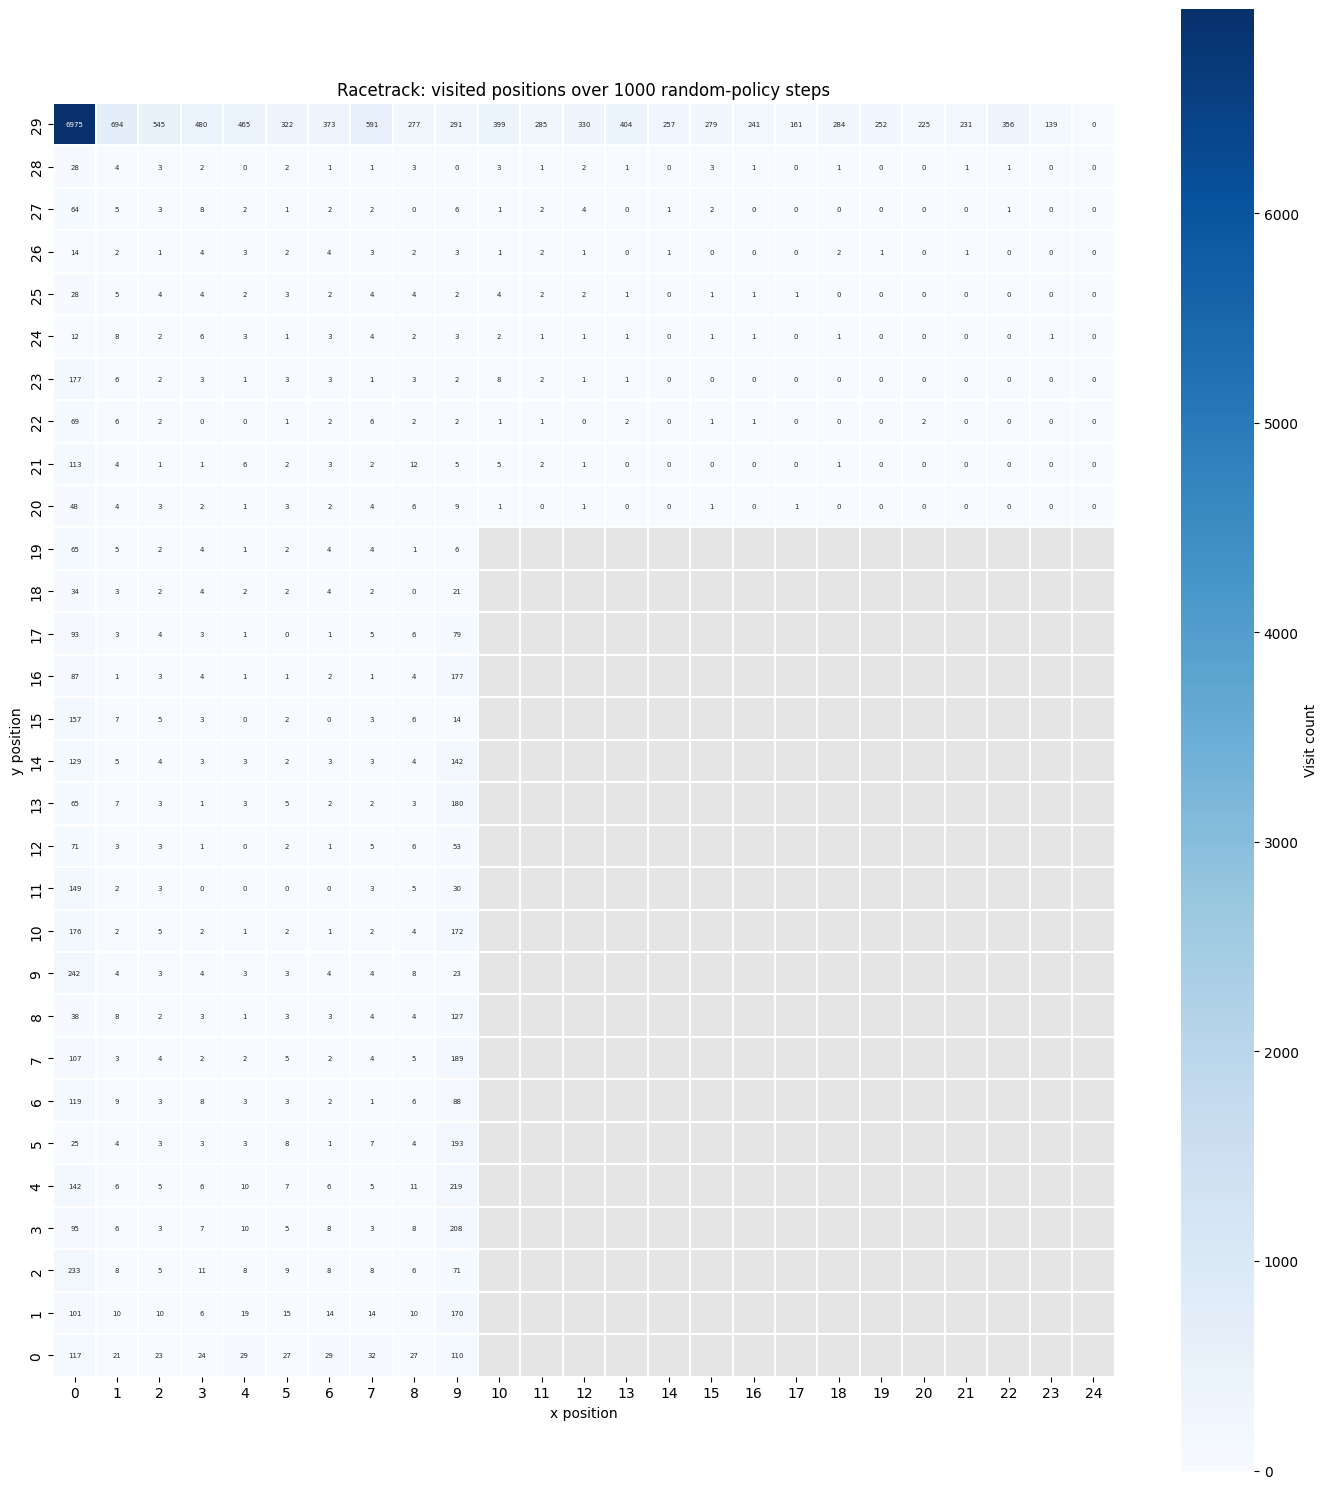

{'finished': 100, 'crashed': 0}


In [69]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from racetrack import RacetrackEnv

track_env = RacetrackEnv()
n_steps = 1000
visits = np.zeros((track_env.height, track_env.width), dtype=int)

track_env.reset()

episode_results = {
    "finished": 0,
    "crashed": 0
}
episodes = 0
while episodes != 100:
    x, y = track_env.pos
    visits[y, x] += 1
    action = track_env.action_space.sample()
    observation, reward, terminated, truncated, info = track_env.step(action)
    done = terminated or truncated
    if done:
        if info["finished"]:
            episode_results["finished"] += 1
            episodes += 1
            track_env.reset()

mask = ~track_env.track
fig, ax = plt.subplots(figsize=(14, 15))
sns.heatmap(
    visits.astype(float),
    mask=mask,
    cmap="Blues",
    annot=True,
    fmt=".0f",
    annot_kws={"size": 5},
    cbar_kws={"label": "Visit count"},
    linewidths=0.1,
    linecolor="white",
    square=True,
    ax=ax,
)
ax.set_facecolor("#e5e5e5")
ax.invert_yaxis()
ax.set_xlabel("x position")
ax.set_ylabel("y position")
ax.set_title(f"Racetrack: visited positions over {n_steps} random-policy steps")
plt.tight_layout()
plt.show()
print(episode_results)

# Solving Markov Decision Problems via Monte Carlo & SARSA

In [18]:
class agent_monte_carlo:
    '''A class to manage the agent'''
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config, a dictionary specifying the track dimensions and initial state
        '''
        self.config = config
        self.q_map = {}

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@    
    def update_Q(self,trajectory):
        """
        trajectory is stored as a single (x, y, vx, vy, action, reward)
        """
        state_and_action_pair = trajectory[5:]
        if ()
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@    
    def pi(self,state,epsilon):
        n_actions = 9
        
        action_values = [self.q_map.get((state, a), 0.0) for a in range(n_actions)]        

        max_val = max(action_values)
        best_actions = [a for a, val in enumerate(action_values) if val == max_val]
        best_action = np.random.choice(best_actions)
        
        probs = np.ones(n_actions) * (epsilon / n_actions)
        
        probs[best_action] += (1.0 - epsilon)
        
        chosen_action = np.random.choice(n_actions, p=probs)
        return chosen_action

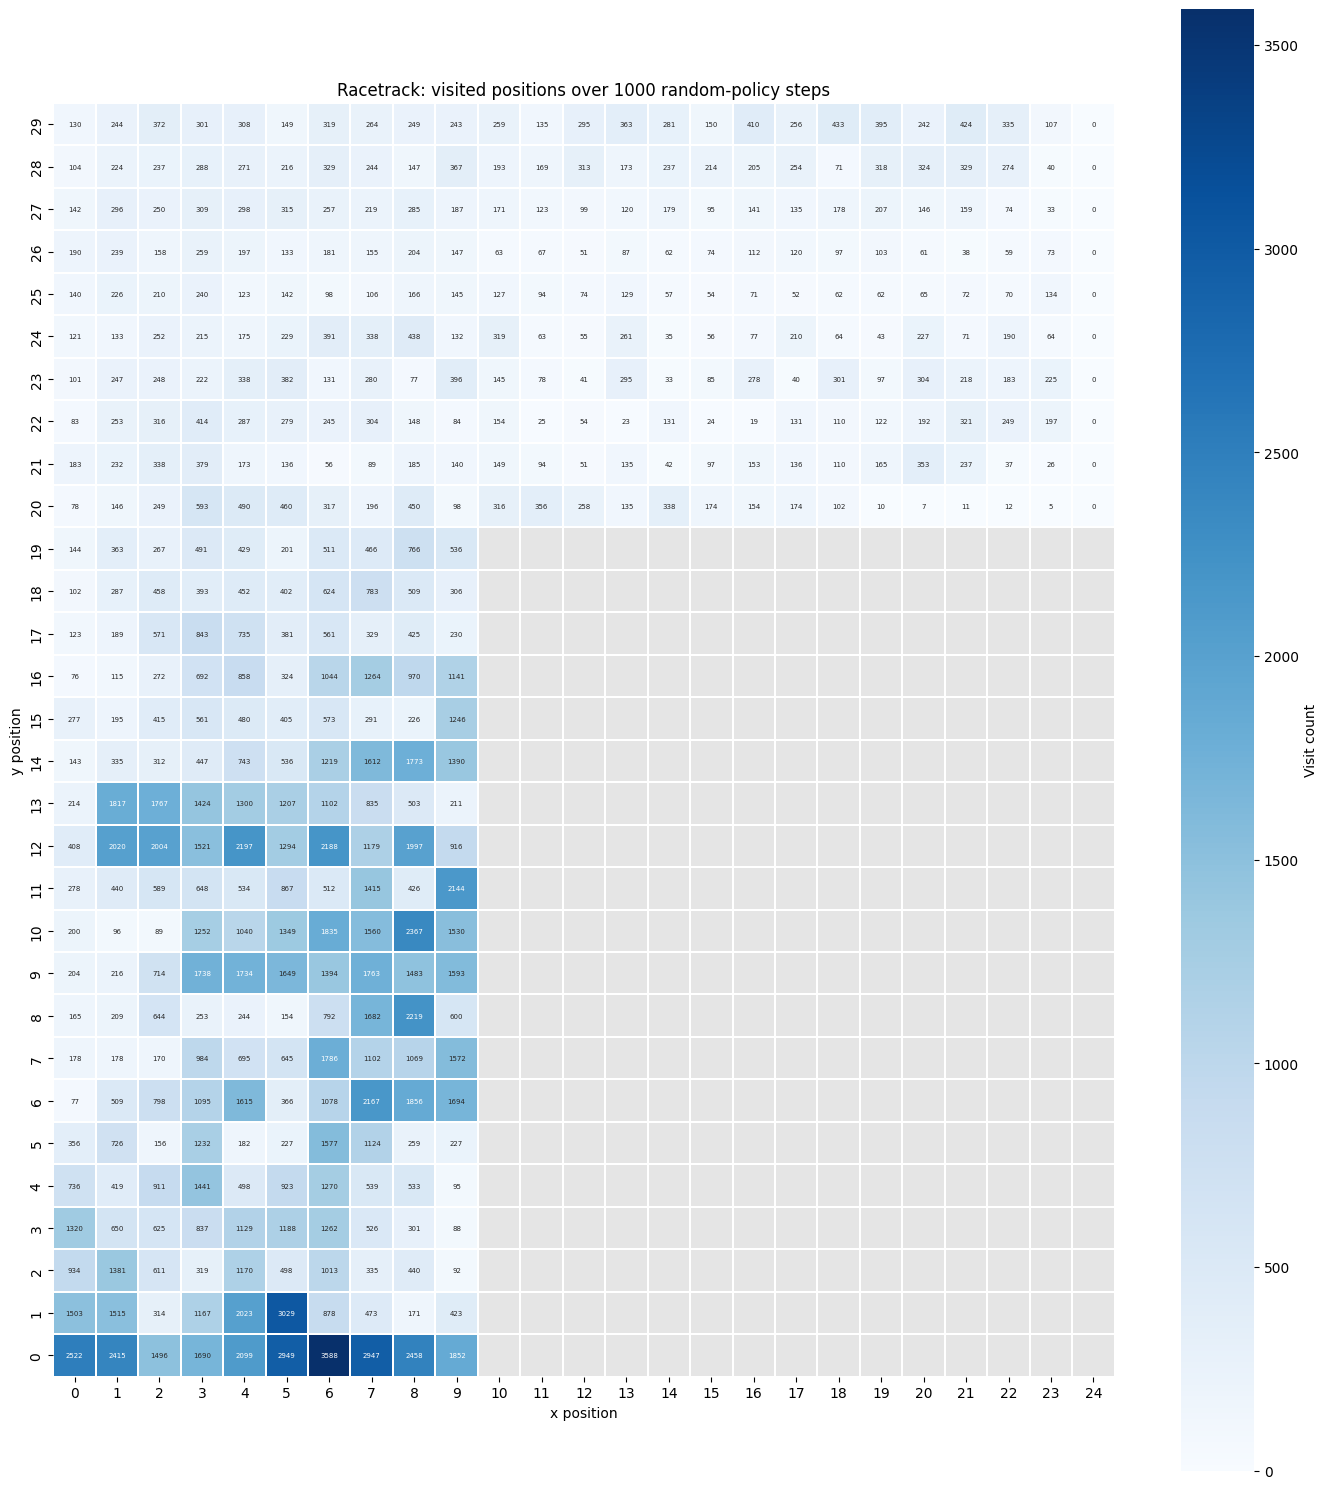

{'finished': 794, 'crashed': 7206, 'episode_lengths': [26, 28, 17, 26, 17, 21, 21, 22, 25, 21, 29, 30, 20, 31, 31, 19, 26, 21, 20, 45, 44, 37, 49, 43, 35, 32, 20, 32, 32, 29, 25, 20, 38, 22, 28, 30, 51, 53, 26, 27, 28, 48, 31, 30, 32, 22, 27, 32, 37, 31, 23, 32, 35, 50, 29, 24, 24, 49, 47, 25, 34, 40, 57, 43, 17, 28, 51, 25, 37, 58, 20, 26, 58, 30, 41, 34, 44, 55, 35, 22, 44, 61, 42, 29, 62, 51, 49, 42, 30, 27, 32, 49, 32, 66, 33, 34, 49, 42, 49, 25, 20, 46, 64, 61, 28, 69, 30, 33, 23, 38, 39, 22, 61, 81, 53, 39, 37, 24, 21, 59, 19, 45, 79, 40, 39, 33, 31, 49, 24, 40, 55, 50, 33, 58, 51, 48, 51, 47, 64, 56, 41, 30, 31, 55, 28, 66, 70, 51, 59, 17, 54, 57, 42, 27, 38, 59, 23, 44, 34, 55, 43, 22, 53, 30, 33, 27, 48, 62, 45, 40, 53, 47, 28, 32, 22, 31, 32, 20, 48, 34, 33, 35, 44, 36, 34, 56, 33, 50, 56, 35, 50, 45, 42, 61, 28, 47, 50, 46, 50, 36, 62, 35, 38, 23, 67, 45, 38, 30, 34, 23, 48, 57, 54, 39, 39, 55, 47, 53, 23, 46, 36, 55, 60, 42, 43, 45, 32, 27, 35, 45, 42, 20, 45, 37, 64, 21, 3

In [19]:
import importlib
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from racetrack import RacetrackEnv
from IPython.display import clear_output
from time import sleep

agent = agent_monte_carlo({
    "discount": 0.9
})


track_env = RacetrackEnv(soft_reset=True)
n_steps = 1000
visits = np.zeros((track_env.height, track_env.width), dtype=int)

track_env.reset()

episode_results = {
    "finished": 0,
    "crashed": 0,
    "episode_lengths": [],
    "rewards": []
}
episodes = 0
epsilon = 0.1

while episodes != 8000:

    trajectory = []
    done = False
    action_set = set()
    clear_output(wait=True)
    if episodes % 100 == 0:
        print(f"Episode {episodes}")
    while not done:
        x, y = track_env.pos
        vx, vy = track_env.vel
        state = (x, y, vx, vy)
        visits[y, x] += 1
        # sleep(0.01)
        # clear_output(wait=True)
        # print(track_env.render())
        action = agent.pi(state, epsilon)
        action_set.add(action)

        observation, reward, terminated, truncated, info = track_env.step(action)
        crashed = info.get("crashed", None)
        done = terminated or truncated
        
        # Record the step into the trajectory list
        trajectory.append((x, y, vx, vy, action, reward))
        
    if info["finished"]:
        episode_results["finished"] += 1
        episode_results["episode_lengths"].append(track_env.steps)
    else:
        episode_results["crashed"] += 1
    episode_results["rewards"].append(reward)

    episodes += 1
    track_env.reset()
    agent.update_Q(trajectory)

mask = ~track_env.track
fig, ax = plt.subplots(figsize=(14, 15))
sns.heatmap(
    visits.astype(float),
    mask=mask,
    cmap="Blues",
    annot=True,
    fmt=".0f",
    annot_kws={"size": 5},
    cbar_kws={"label": "Visit count"},
    linewidths=0.1,
    linecolor="white",
    square=True,
    ax=ax,
)
ax.set_facecolor("#e5e5e5")
ax.invert_yaxis()
ax.set_xlabel("x position")
ax.set_ylabel("y position")
ax.set_title(f"Racetrack: visited positions over {n_steps} random-policy steps")
plt.tight_layout()
plt.show()
print(episode_results)

In [20]:
def print_episode_results(results):
    print(f"finished: {results['finished']}")
    print(f"crashed: {results['crashed']}")
    print(f"average_episode_length: {sum(results['episode_lengths'])/len(results['episode_lengths'])}")
    print(f"average_reward: {sum(results['rewards'])/len(results['rewards'])}")
print_episode_results(episode_results)

finished: 794
crashed: 7206
average_episode_length: 44.03904282115869
average_reward: 0.0835519438122589


In [ ]:
class agent_sarsa:
    '''A class to manage the agent'''
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config, a dictionary specifying the track dimensions and initial state
        '''
        self.config = config
        self.z_map = {}
        self.q_map = {}

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@    
    def update_Q(self,trajectory):
        """
        trajectory is stored as (x, y, vx, vy, action, reward)
        """
        T = len(trajectory)

        
        
        for t in range(T):
            a =
            

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@    
    def pi(self,state,epsilon):
        n_actions = 9
        
        action_values = [self.q_map.get((state, a), 0.0) for a in range(n_actions)]        

        max_val = max(action_values)
        best_actions = [a for a, val in enumerate(action_values) if val == max_val]
        best_action = np.random.choice(best_actions)
        
        probs = np.ones(n_actions) * (epsilon / n_actions)
        
        probs[best_action] += (1.0 - epsilon)
        
        chosen_action = np.random.choice(n_actions, p=probs)
        return chosen_action